# 291. Does kmerseek find known Pfam domains, on dark proteins and on placed ones? Which alphabets and k do best?

**Question.** When kmerseek reports a region between a query protein and a Swiss-Prot
target, and the target's Pfam domain is carried over to the query, is it the domain the
query is known to have, in the right place? Scored with the same metrics as the QfO Pfam
region benchmark, for kmerseek and for phmmer, jackhmmer and mmseqs2.

**Decision this informs.** Whether the paper can say kmerseek finds domains on proteins
the sequence tools miss, and which alphabets and k to carry forward.

**Decision rule.** It was written after the per-species totals of section 2 were first
seen, so it is not blind to them. kmerseek finds known domains on dark proteins if its best
setting's Fmax on dark proteins (no tool hit with E < 1) is at least phmmer's in at least 3
of the 4 species. Settings are ranked by interval Fmax on the placed control, the median
over the four species.

**Metrics** (QfO's `evaluate_domain_calls.py` and `cafa_metrics.py`, from main):
- A **call** is a region's query interval labelled with the Pfam family of the target
  domain that covers at least half of the region's target side.
- A call is a **true positive** when the query has that family and the call's interval
  overlaps a real instance of it with IoU at least 0.5. IoU is the overlap between the call
  and the domain divided by their union.
- **Fmax** is CAFA's protein-centric F-measure: precision averaged over proteins with a
  call, recall over proteins with a domain, the best value over score thresholds. Higher is
  better; 0 means no correct call at any threshold.
- **Family Fmax** is the same with placement ignored: only whether the right family was
  named on the protein.
- **Recall (reachable)** counts only domains whose family exists somewhere in the target
  database, since no tool can transfer a family the database lacks.

**Data.** Dark-set midi run `ladder-0.4-midi` (PR 57,
[seanome/2024-kmerseek-analysis#57](https://github.com/seanome/2024-kmerseek-analysis/pull/57)).
kmerseek: image `olgabot/kmerseek:0.4.0-rc5`, `extend`, mask off, the 230 settings the run's
last gain step read (some refused for lack of a Karlin-Altschul fit and make no calls),
regions with E < 10, ranked by `region_enrichment` after a Bonferroni filter at 0.05 (QfO's
defaults). Rows whose target coordinates do not match the target sequence (kmerseek 0.4.0
alias bug, kmerseek PR 141) were dropped: 782_859 of 34.2 million. Sequence tools: rerun on
the same proteins on 2026-10-14 with the run's own flags (E <= 10 reported, jackhmmer 3
iterations, mmseqs2 `-s 7`, 3 iterations), adding query coordinates; the hits match the
original run's exactly (`rerun_reproduction.txt`).
- **Queries:** dark proteins of human, worm, yeast and *Borrelia*: no phmmer, jackhmmer or
  mmseqs2 hit with E < 1 (and the smaller set with none below 10); and 1_000 placed proteins
  per species drawn at random (seed 0) as the positive control.
- **Target database:** reviewed Swiss-Prot minus the query's clade (Mammalia, Chromadorea,
  Saccharomycetes, Spirochaetia).
- **Pfam domains** for queries and targets: InterPro 110.0 `protein2ipr.dat.gz`, Pfam 38.2
  rows (families not integrated into InterPro, about 1_000 of 30_134, are absent).

In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from PIL import Image

import pubfig as pf

pf.use_style()
pl.Config.set_tbl_rows(80)
pl.Config.set_tbl_cols(20)
pl.Config.set_tbl_width_chars(220)
pl.Config.set_fmt_str_lengths(50)

DATA = Path("data/291_dark_fmax")
FIGURES = Path("figures/291_dark_fmax")
IMAGE = "olgabot/kmerseek:0.4.0-rc5"
SPECIES = ["human", "worm", "yeast", "borrelia"]
SPECIES_LABEL = {
    "human": "human",
    "worm": "worm",
    "yeast": "yeast",
    "borrelia": "Borrelia",
}
ORDER = {s: i for i, s in enumerate(SPECIES)}
TOOLS = ["phmmer", "jackhmmer", "mmseqs2"]
TOOL_COLOUR = {
    "phmmer": pf.OKABE_ITO["vermillion"],
    "jackhmmer": pf.OKABE_ITO["reddish_purple"],
    "mmseqs2": pf.OKABE_ITO["bluish_green"],
}
TOOL_MARKER = {"phmmer": "o", "jackhmmer": "s", "mmseqs2": "^"}
KMERSEEK_COLOUR = pf.OKABE_ITO["blue"]
TOP_N = 15
SET_LABEL = {
    "dark_E1": "dark (no tool hit with E < 1)",
    "dark_E10": "dark (no tool hit with E < 10)",
    "placed": "placed (random 1_000 with a tool hit E < 1)",
}
TARGET_LINE = "Query: each proteome. Target: Swiss-Prot minus the query's clade. Pfam 38.2 (InterPro 110.0)."


def save_figure(fig, name):
    pf.save(fig, FIGURES / name)
    png = (FIGURES / name).with_suffix(".png")
    with Image.open(png) as im:
        dpi = im.info.get("dpi")
        pal = im.convert("RGB").quantize(colors=256, dither=Image.Dither.NONE)
    pal.save(png, optimize=True, **({"dpi": dpi} if dpi else {}))
    print(f"saved {png}")


VARIANT = re.compile(
    r"^(?P<alphabet>.+)\.k(?P<k>\d+)\.s(?P<scaled>\d+)\.lc\w+\.(?P<ext>.+)$"
)
m = pl.read_csv(DATA / "dark_fmax_metrics.csv.gz", infer_schema_length=10_000)
# QfO scores each arm with and without merging duplicate transferred calls; this notebook
# reads the default, unmerged one.
m = m.filter(pl.col("dedup_transfers") == False)
km = (
    m.filter(pl.col("tool") == "kmerseek")
    .with_columns(
        pl.col("variant").str.extract(VARIANT.pattern, 1).alias("alphabet"),
        pl.col("variant").str.extract(VARIANT.pattern, 2).cast(pl.Int64).alias("k"),
        pl.col("variant")
        .str.extract(VARIANT.pattern, 3)
        .cast(pl.Int64)
        .alias("scaled"),
    )
    .with_columns(
        pl.col("alphabet").str.extract(r"(\d+)$", 1).cast(pl.Int64).alias("letters"),
        (
            pl.col("alphabet")
            + " k"
            + pl.col("k").cast(pl.Utf8)
            + " scaled "
            + pl.col("scaled").cast(pl.Utf8)
        ).alias("setting"),
    )
)
tools = m.filter(pl.col("tool").is_in(TOOLS))
assert km["alphabet"].null_count() == 0
print(f"{m.height} metric rows; kmerseek settings per species and query set:")
print(
    km.group_by("species", "truth_set")
    .len()
    .sort("truth_set", pl.col("species").replace_strict(ORDER))
)
print("\nPfam domains per query set (from the build step):")
print((DATA / "build.log").read_text().strip())
print(
    "\nSequence-tool rerun against the original run's hits (query, target, target start, end, E-value):"
)
print((DATA / "rerun_reproduction.txt").read_text().strip())

2796 metric rows; kmerseek settings per species and query set:
shape: (12, 3)
┌──────────┬───────────┬─────┐
│ species  ┆ truth_set ┆ len │
│ ---      ┆ ---       ┆ --- │
│ str      ┆ str       ┆ u32 │
╞══════════╪═══════════╪═════╡
│ human    ┆ dark_E1   ┆ 230 │
│ worm     ┆ dark_E1   ┆ 230 │
│ yeast    ┆ dark_E1   ┆ 230 │
│ borrelia ┆ dark_E1   ┆ 230 │
│ human    ┆ dark_E10  ┆ 230 │
│ worm     ┆ dark_E10  ┆ 230 │
│ yeast    ┆ dark_E10  ┆ 230 │
│ borrelia ┆ dark_E10  ┆ 230 │
│ human    ┆ placed    ┆ 230 │
│ worm     ┆ placed    ┆ 230 │
│ yeast    ┆ placed    ┆ 230 │
│ borrelia ┆ placed    ┆ 230 │
└──────────┴───────────┴─────┘

Pfam domains per query set (from the build step):
human dark_E1: 1696 proteins, 1057 with a Pfam domain, 1456 domains
human dark_E10: 442 proteins, 217 with a Pfam domain, 375 domains
human placed: 1000 proteins, 958 with a Pfam domain, 2418 domains
human reference: 505077 proteins, 477873 with a Pfam domain, 796859 domains
worm dark_E1: 4667 proteins, 1929 wit

## 1. Dark proteins: does any tool find their known domains?

For each species, Fmax and reachable recall of the three sequence tools and of kmerseek's
best setting (highest Fmax of the 230) and median setting. Dark at E < 1 means the tools
have no hit below 1; any correct call a tool makes here comes from its hits with E between
1 and 10. Higher is better; 0 means no correct domain at any threshold.

shape: (48, 10)
┌───────────┬──────────┬─────────────────────────────────────────────┬────────┬─────────────┬──────────────────┬─────────┬───────────────────┬───────────────────────┬───────────────────┐
│ truth_set ┆ species  ┆ who                                         ┆ fmax   ┆ family_fmax ┆ recall_reachable ┆ n_calls ┆ n_instances_found ┆ n_reachable_instances ┆ n_truth_instances │
│ ---       ┆ ---      ┆ ---                                         ┆ ---    ┆ ---         ┆ ---              ┆ ---     ┆ ---               ┆ ---                   ┆ ---               │
│ str       ┆ str      ┆ str                                         ┆ f64    ┆ f64         ┆ f64              ┆ f64     ┆ f64               ┆ f64                   ┆ f64               │
╞═══════════╪══════════╪═════════════════════════════════════════════╪════════╪═════════════╪══════════════════╪═════════╪═══════════════════╪═══════════════════════╪═══════════════════╡
│ dark_E1   ┆ human    ┆ phmmer                  

saved figures/291_dark_fmax/dark_proteins_fmax_recall_kmerseek_vs_tools_midi_pfam38.png


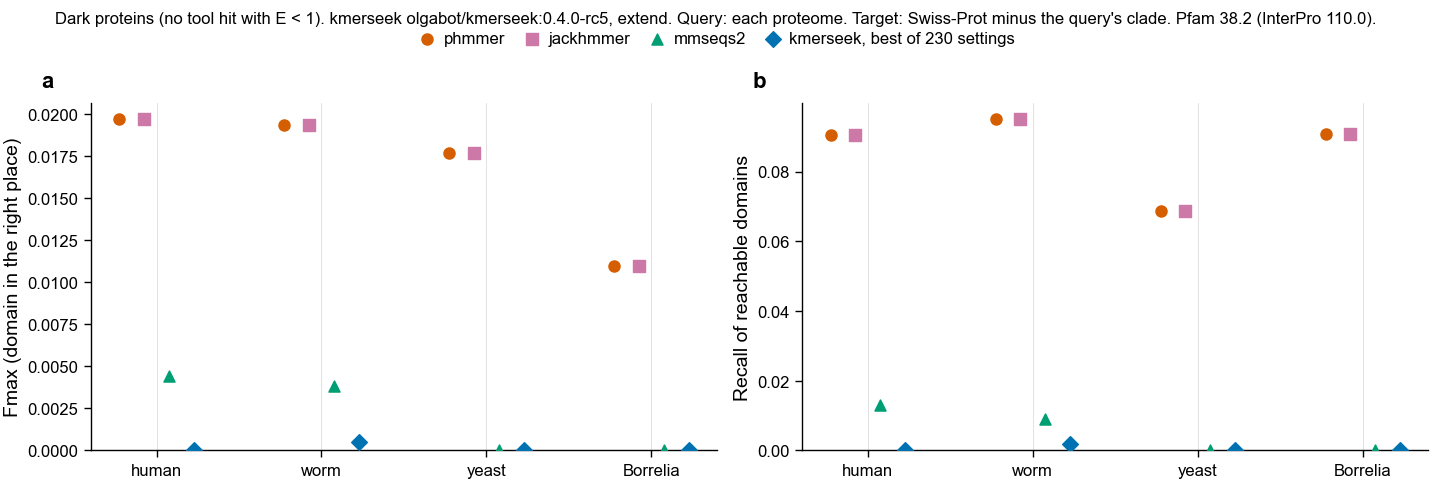

In [2]:
cols = [
    "fmax",
    "family_fmax",
    "recall_reachable",
    "n_calls",
    "n_instances_found",
    "n_reachable_instances",
    "n_truth_instances",
]
dark_rows = []
for ts in ("dark_E1", "dark_E10"):
    for s in SPECIES:
        for t in TOOLS:
            r = tools.filter(
                (pl.col("truth_set") == ts)
                & (pl.col("species") == s)
                & (pl.col("tool") == t)
            )
            dark_rows.append(
                {
                    "truth_set": ts,
                    "species": s,
                    "who": t,
                    **{c: r[c].item() for c in cols},
                }
            )
        k = km.filter((pl.col("truth_set") == ts) & (pl.col("species") == s))
        best = k.sort(
            "fmax", "n_instances_found", "setting", descending=[True, True, False]
        ).row(0, named=True)
        who = (
            f"kmerseek best: {best['setting']}"
            if best["fmax"] > 0
            else "kmerseek best: none (all 230 settings at 0)"
        )
        dark_rows.append(
            {"truth_set": ts, "species": s, "who": who, **{c: best[c] for c in cols}}
        )
        dark_rows.append(
            {
                "truth_set": ts,
                "species": s,
                "who": "kmerseek median of 230 settings",
                **{c: float(k[c].median()) for c in cols},
            }
        )
        dark_rows.append(
            {
                "truth_set": ts,
                "species": s,
                "who": "kmerseek, all settings: domains found (sum)",
                "n_instances_found": int(k["n_instances_found"].sum()),
                "n_calls": int(k["n_calls"].sum()),
            }
        )
dark = pl.DataFrame(dark_rows, infer_schema_length=None)
print(dark.with_columns(pl.col(pl.Float64).round(4)))

fig, axs = pf.figure(pf.TWO_COLUMN_MM, 62, ncols=2)
for ax, metric, label in (
    (axs[0], "fmax", "Fmax (domain in the right place)"),
    (axs[1], "recall_reachable", "Recall of reachable domains"),
):
    x = np.arange(len(SPECIES))
    for i, t in enumerate(TOOLS):
        y = [
            dark.filter(
                (pl.col("truth_set") == "dark_E1")
                & (pl.col("species") == s)
                & (pl.col("who") == t)
            )[metric].item()
            for s in SPECIES
        ]
        ax.scatter(
            x + (i - 1.5) * 0.15,
            y,
            color=TOOL_COLOUR[t],
            marker=TOOL_MARKER[t],
            s=16,
            zorder=3,
            label=t,
        )
    y = [
        dark.filter(
            (pl.col("truth_set") == "dark_E1")
            & (pl.col("species") == s)
            & pl.col("who").str.starts_with("kmerseek best")
        )[metric].item()
        for s in SPECIES
    ]
    ax.scatter(
        x + 1.5 * 0.15,
        y,
        color=KMERSEEK_COLOUR,
        marker="D",
        s=16,
        zorder=3,
        label="kmerseek, best of 230 settings",
    )
    for xi in x:
        ax.axvline(xi, color="#dddddd", lw=0.3, zorder=0)
    ax.set_xticks(x, [SPECIES_LABEL[s] for s in SPECIES])
    ax.set_ylabel(label)
    ax.set_ylim(0, None)
for ax, letter in zip(axs, "ab"):
    pf.panel_label(ax, letter)
pf.shared_legend(
    fig,
    ncol=4,
    title=f"Dark proteins (no tool hit with E < 1). kmerseek {IMAGE}, extend. {TARGET_LINE}",
)
save_figure(fig, "dark_proteins_fmax_recall_kmerseek_vs_tools_midi_pfam38")

## 2. Placed proteins (positive control): kmerseek against the tools

The same metrics on 1_000 random placed proteins per species, which have a homolog in the
target database. Each blue point is one kmerseek setting; the tools are the coloured marks.
Panel a scores the domain in the right place (IoU at least 0.5); panel b only whether the
right family was named on the protein. Higher is better.

shape: (4, 11)
┌──────────┬────────────┬───────────────────┬──────────────────────┬──────────────────────────┬────────────────┬──────────────┬─────────────┬───────────────────────┬─────────────────────┬────────────────────┐
│ species  ┆ n_settings ┆ kmerseek_max_fmax ┆ kmerseek_median_fmax ┆ kmerseek_max_family_fmax ┆ jackhmmer_fmax ┆ mmseqs2_fmax ┆ phmmer_fmax ┆ jackhmmer_family_fmax ┆ mmseqs2_family_fmax ┆ phmmer_family_fmax │
│ ---      ┆ ---        ┆ ---               ┆ ---                  ┆ ---                      ┆ ---            ┆ ---          ┆ ---         ┆ ---                   ┆ ---                 ┆ ---                │
│ str      ┆ u32        ┆ f64               ┆ f64                  ┆ f64                      ┆ f64            ┆ f64          ┆ f64         ┆ f64                   ┆ f64                 ┆ f64                │
╞══════════╪════════════╪═══════════════════╪══════════════════════╪══════════════════════════╪════════════════╪══════════════╪═════════════╪════════

saved figures/291_dark_fmax/placed_control_fmax_every_setting_vs_tools_midi_pfam38.png


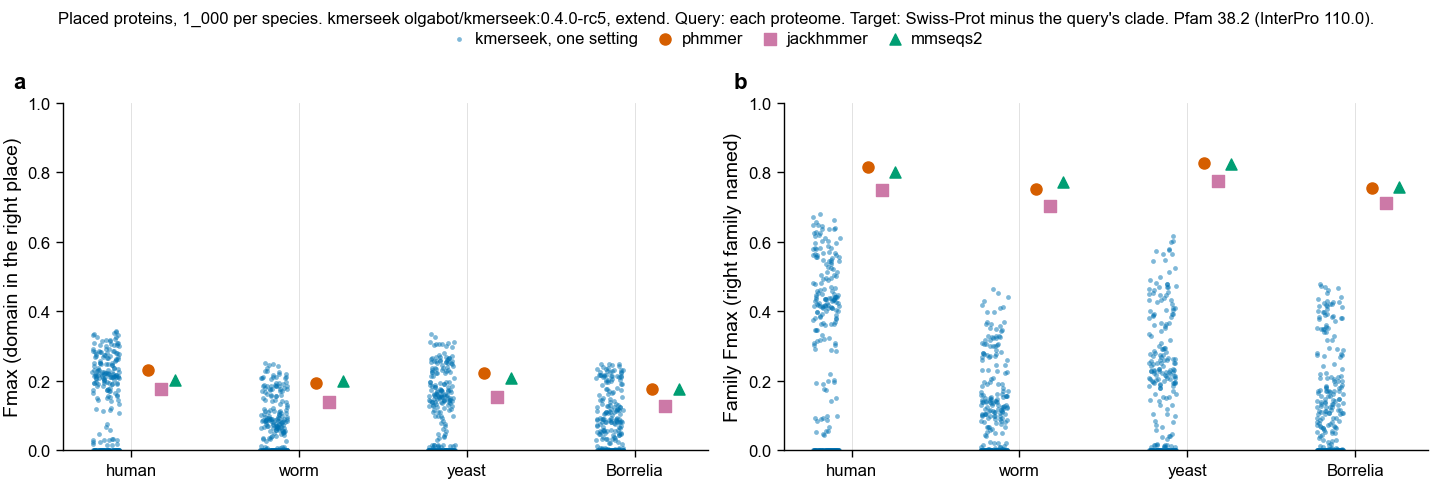

In [3]:
placed = km.filter(pl.col("truth_set") == "placed")
summary = (
    placed.group_by("species")
    .agg(
        pl.len().alias("n_settings"),
        pl.col("fmax").max().round(3).alias("kmerseek_max_fmax"),
        pl.col("fmax").median().round(3).alias("kmerseek_median_fmax"),
        pl.col("family_fmax").max().round(3).alias("kmerseek_max_family_fmax"),
    )
    .join(
        tools.filter(pl.col("truth_set") == "placed")
        .pivot(on="tool", index="species", values="fmax")
        .rename({t: f"{t}_fmax" for t in TOOLS}),
        on="species",
    )
    .join(
        tools.filter(pl.col("truth_set") == "placed")
        .pivot(on="tool", index="species", values="family_fmax")
        .rename({t: f"{t}_family_fmax" for t in TOOLS}),
        on="species",
    )
    .sort(pl.col("species").replace_strict(ORDER))
)
print(summary.with_columns(pl.col(pl.Float64).round(3)))

fig, axs = pf.figure(pf.TWO_COLUMN_MM, 62, ncols=2)
rng = np.random.default_rng(0)
for ax, metric, label in (
    (axs[0], "fmax", "Fmax (domain in the right place)"),
    (axs[1], "family_fmax", "Family Fmax (right family named)"),
):
    for xi, s in enumerate(SPECIES):
        v = placed.filter(pl.col("species") == s)[metric].to_numpy()
        ax.scatter(
            xi - 0.15 + rng.uniform(-0.08, 0.08, len(v)),
            v,
            s=3,
            color=KMERSEEK_COLOUR,
            alpha=0.5,
            linewidths=0,
            zorder=2,
            label="kmerseek, one setting",
        )
        for i, t in enumerate(TOOLS):
            y = tools.filter(
                (pl.col("truth_set") == "placed")
                & (pl.col("species") == s)
                & (pl.col("tool") == t)
            )[metric].item()
            ax.scatter(
                [xi + 0.1 + i * 0.08],
                [y],
                color=TOOL_COLOUR[t],
                marker=TOOL_MARKER[t],
                s=16,
                zorder=3,
                label=t,
            )
        ax.axvline(xi, color="#dddddd", lw=0.3, zorder=0)
    ax.set_xticks(range(len(SPECIES)), [SPECIES_LABEL[s] for s in SPECIES])
    ax.set_ylim(0, 1)
    ax.set_ylabel(label)
for ax, letter in zip(axs, "ab"):
    pf.panel_label(ax, letter)
pf.shared_legend(
    fig,
    ncol=4,
    title=f"Placed proteins, 1_000 per species. kmerseek {IMAGE}, extend. {TARGET_LINE}",
)
save_figure(fig, "placed_control_fmax_every_setting_vs_tools_midi_pfam38")

## 3. Which alphabets and k find known domains best?

On the placed control (on dark proteins every setting is at or near 0). The heatmap is the
median over the four species of interval Fmax, scaled 1, alphabets grouped by number of
letters. A blank square is a k the run did not search for that alphabet. Higher is better.

saved figures/291_dark_fmax/kmerseek_fmax_heatmap_alphabet_k_placed_midi_pfam38.png
Top 15 settings by median Fmax on the placed control (4 species):
shape: (15, 7)
┌───────────────────────────────────┬─────────┬─────────────┬──────────┬────────────────────┬─────────────────────────┬───────────────┐
│ setting                           ┆ letters ┆ median_fmax ┆ min_fmax ┆ median_family_fmax ┆ median_recall_reachable ┆ median_iou_tp │
│ ---                               ┆ ---     ┆ ---         ┆ ---      ┆ ---                ┆ ---                     ┆ ---           │
│ str                               ┆ i64     ┆ f64         ┆ f64      ┆ f64                ┆ f64                     ┆ f64           │
╞═══════════════════════════════════╪═════════╪═════════════╪══════════╪════════════════════╪═════════════════════════╪═══════════════╡
│ mmseqs12 k8 scaled 1              ┆ 12      ┆ 0.289       ┆ 0.22     ┆ 0.503              ┆ 0.345                   ┆ 0.646         │
│ hsdm17 k6 scaled 

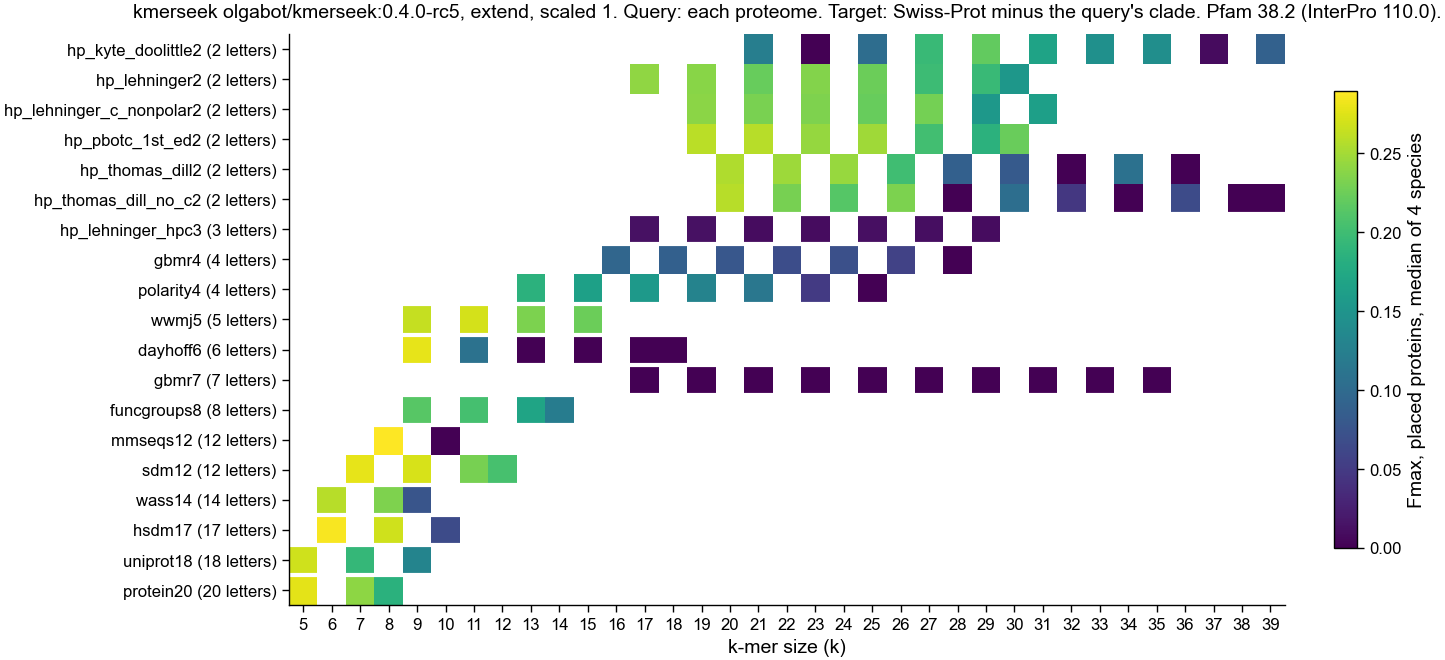

In [4]:
by_setting = (
    placed.group_by("setting", "alphabet", "k", "scaled", "letters")
    .agg(
        pl.len().alias("n_species"),
        pl.col("fmax").median().alias("median_fmax"),
        pl.col("fmax").min().alias("min_fmax"),
        pl.col("family_fmax").median().alias("median_family_fmax"),
        pl.col("recall_reachable").median().alias("median_recall_reachable"),
        pl.col("median_iou_tp").median().alias("median_iou_tp"),
    )
    .filter(pl.col("n_species") == len(SPECIES))
)
s1 = by_setting.filter(pl.col("scaled") == 1)
alphabets = s1.select("alphabet", "letters").unique().sort("letters", "alphabet")
ks = sorted(s1["k"].unique().to_list())
grid = np.full((alphabets.height, len(ks)), np.nan)
names = alphabets["alphabet"].to_list()
for r in s1.iter_rows(named=True):
    grid[names.index(r["alphabet"]), ks.index(r["k"])] = r["median_fmax"]
fig, ax = pf.figure(pf.TWO_COLUMN_MM, 85)
im = ax.imshow(
    grid,
    aspect="auto",
    cmap=plt.get_cmap("viridis"),
    vmin=np.nanmin(grid),
    vmax=np.nanmax(grid),
)
ax.set_xticks(range(len(ks)), ks)
ax.set_yticks(
    range(len(names)), [f"{a} ({n} letters)" for a, n in alphabets.iter_rows()]
)
ax.set_xlabel("k-mer size (k)")
for yi in range(1, alphabets.height):
    if alphabets["letters"][yi] != alphabets["letters"][yi - 1]:
        ax.axhline(yi - 0.5, color="white", lw=1.5)
cb = fig.colorbar(im, ax=ax, shrink=0.8)
cb.set_label("Fmax, placed proteins, median of 4 species")
ax.set_title(f"kmerseek {IMAGE}, extend, scaled 1. {TARGET_LINE}")
save_figure(fig, "kmerseek_fmax_heatmap_alphabet_k_placed_midi_pfam38")

top = by_setting.sort("median_fmax", "setting", descending=[True, False]).head(TOP_N)
print(f"Top {TOP_N} settings by median Fmax on the placed control (4 species):")
print(
    top.select(
        "setting",
        "letters",
        "median_fmax",
        "min_fmax",
        "median_family_fmax",
        "median_recall_reachable",
        "median_iou_tp",
    ).with_columns(pl.col(pl.Float64).round(3))
)
print("\nBest setting within each alphabet (median Fmax, placed):")
print(
    by_setting.sort("median_fmax", descending=True)
    .group_by("alphabet", maintain_order=True)
    .first()
    .select("alphabet", "letters", "setting", "median_fmax", "median_family_fmax")
    .with_columns(pl.col(pl.Float64).round(3))
)

saved figures/291_dark_fmax/kmerseek_top_settings_fmax_placed_vs_tools_midi_pfam38.png


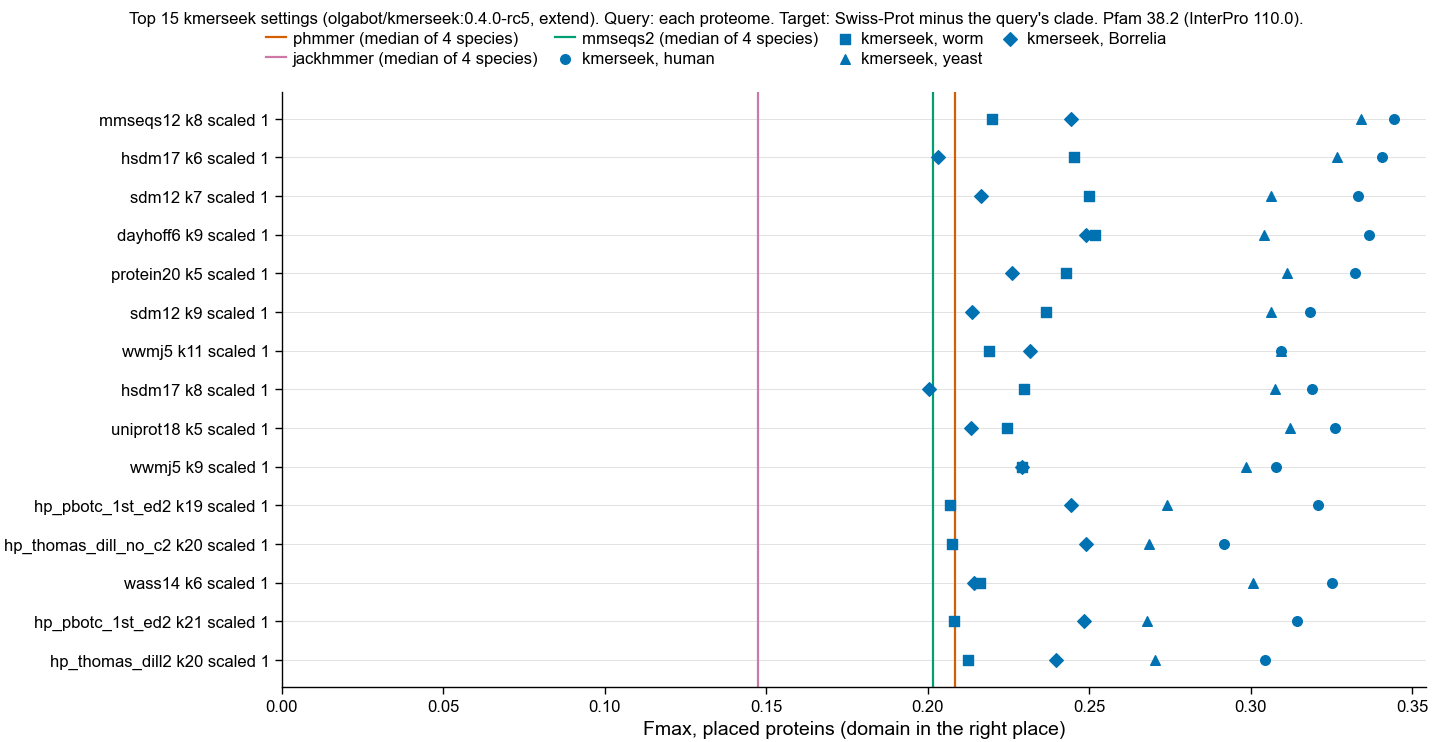

In [5]:
rows = top["setting"].to_list()[::-1]
fig, ax = pf.figure(pf.TWO_COLUMN_MM, 95)
tp = tools.filter(pl.col("truth_set") == "placed")
for t in TOOLS:
    med = float(tp.filter(pl.col("tool") == t)["fmax"].median())
    ax.axvline(
        med, color=TOOL_COLOUR[t], lw=0.8, zorder=1, label=f"{t} (median of 4 species)"
    )
for yi, st in enumerate(rows):
    ax.axhline(yi, color="#dddddd", lw=0.3, zorder=0)
    sub = placed.filter(pl.col("setting") == st)
    for s, marker in zip(SPECIES, ("o", "s", "^", "D")):
        ax.scatter(
            sub.filter(pl.col("species") == s)["fmax"],
            [yi],
            marker=marker,
            color=KMERSEEK_COLOUR,
            s=12,
            zorder=3,
            label=f"kmerseek, {SPECIES_LABEL[s]}",
        )
ax.set_yticks(range(len(rows)), rows)
ax.set_xlim(0, None)
ax.set_xlabel("Fmax, placed proteins (domain in the right place)")
pf.shared_legend(
    fig, ncol=4, title=f"Top {TOP_N} kmerseek settings ({IMAGE}, extend). {TARGET_LINE}"
)
save_figure(fig, "kmerseek_top_settings_fmax_placed_vs_tools_midi_pfam38")

## Summary & conclusions

**kmerseek finds almost no known domains on dark proteins** (section 1). Over all 230
settings and four species, kmerseek's calls on dark proteins (no tool hit with E < 1)
found 1 known Pfam domain: in worm, under dayhoff6 k9 scaled 1 (Fmax 0.0005). In human it
made 5_845 calls over all settings and found none. phmmer and jackhmmer found 21 (human),
53 (worm), 7 (yeast) and 2 (*Borrelia*) from their hits with E between 1 and 10, for Fmax
0.011-0.020; mmseqs2 found 0-5. On the smaller dark set (no tool hit with E < 10) every
tool and every kmerseek setting is at or near 0. The decision rule (kmerseek's best
setting at least phmmer's Fmax in 3 of 4 species) is not met in any species. The paper
cannot claim kmerseek finds known domains the sequence tools miss.

**On placed proteins kmerseek places domains more precisely than the tools, but names
fewer families** (section 2). Its best setting reaches Fmax 0.344 (human), 0.252 (worm),
0.334 (yeast) and 0.249 (*Borrelia*), against phmmer's 0.231, 0.195, 0.222 and 0.178. On
family Fmax, which ignores placement, the tools lead: phmmer 0.753-0.828 against
kmerseek's best 0.464-0.681. So kmerseek's calls are tighter where they exist, and fewer
proteins get one. The median setting is far lower (Fmax 0.069-0.194).

**Best alphabets and k** (section 3, placed proteins, median of four species): mmseqs12
k8 (0.289), hsdm17 k6 (0.286), sdm12 k7 and dayhoff6 k9 (0.278), protein20 k5 (0.277).
The best two-letter H/P settings are hp_pbotc_1st_ed2 k19 and hp_thomas_dill_no_c2 k20
(0.259). Every top setting is scaled 1, and most alphabets do best at or near the smallest k
searched (hp_kyte_doolittle2, best at k29, is the exception). gbmr4 k16 (0.095) and hp_lehninger_hpc3 k17 (0.013), which reached the most
dark proteins in notebook 289, are among the worst at finding domains: reach without the
right domain. gbmr7 makes almost no calls that survive transfer and the Bonferroni filter
(6 calls on the placed proteins in all) and scores 0.

**Caveats.**
- The truth is Pfam as InterPro 110.0 reports it. A dark protein with no Pfam domain, or a
  domain not integrated into InterPro, cannot be scored, and recall counts only domains
  whose family exists in the target database (232 of 1_456 in human dark proteins).
- kmerseek is ranked by `region_enrichment` after QfO's Bonferroni filter, so the numbers
  compare with QfO. Ranking by 0.4's region E-value was not tried.
- 782_859 of 34.2 million kmerseek regions (2.3%) had target coordinates that do not match
  the target sequence (kmerseek 0.4.0 alias bug, kmerseek PR 141) and were dropped.
- IoU for kmerseek is about one residue short, because its coordinates are 0-based and
  Pfam's 1-based, as in the QfO benchmark.

**Next.** Rank kmerseek by region E-value and rescore; check whether the placed-protein
advantage holds on the held-out half used by the QfO benchmark.